# 03 · Ley de Gutenberg-Richter: Mc y valor b

log10 N(≥M) = a − b·M. Primero la magnitud de completitud (Mc), después b por máxima verosimilitud (Aki-Utsu) con IC 95 % (Shi-Bolt y bootstrap), y como línea base, mínimos cuadrados.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display

from sismos import config, analisis, graficos
from sismos import gutenberg_richter as gr

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
ecuador = pd.read_parquet(config.CATALOGO_ECUADOR)
mundo = pd.read_parquet(config.CATALOGO_CINTURON)
historico = pd.read_parquet(config.CATALOGO_HISTORICO)
resultados = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
print(f"Ecuador: {len(ecuador):,} sismos · mundo M≥5: {len(mundo):,} · histórico M≥6: {len(historico):,}")

Ecuador: 3,214 sismos · mundo M≥5: 87,784 · histórico M≥6: 139


In [2]:
g = resultados['gutenberg_richter_ecuador']
pd.DataFrame({'máxima curvatura': g['maxc'], 'estabilidad de b': g['mbs']})

,máxima curvatura,estabilidad de b
mc,5.000,5.600
n,1280.000,179.000
b,1.305,0.847
a,7.884,5.250
sigma_shi_bolt,0.043,0.065
sigma_aki,0.036,0.063
ic95_bajo,1.220,0.720
ic95_alto,1.389,0.975
ic95_boot_bajo,1.225,0.739
ic95_boot_alto,1.398,1.000


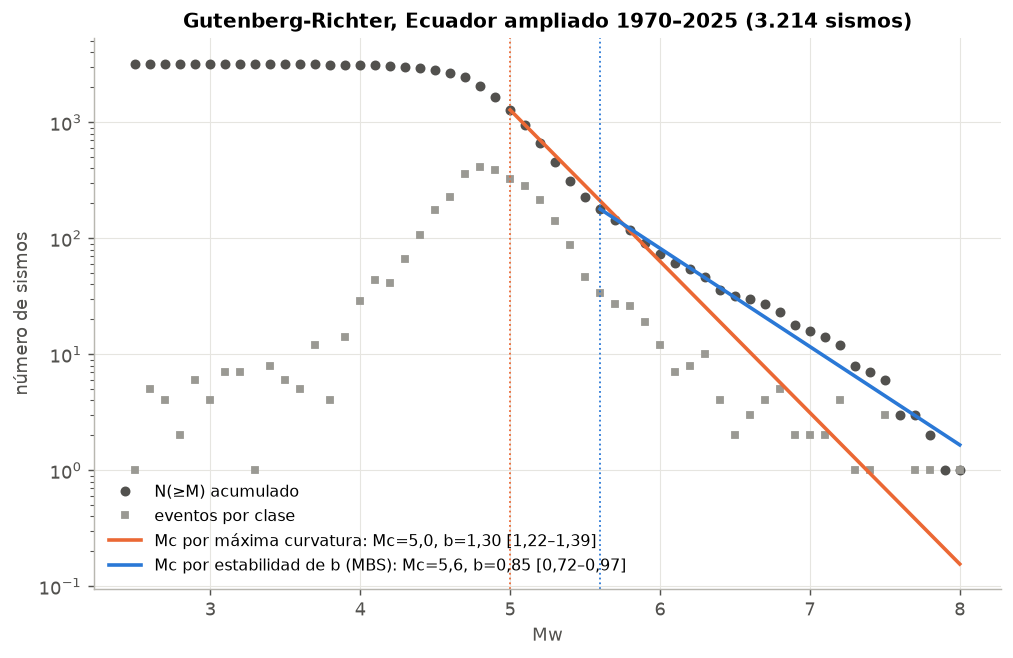

In [3]:
display(Image(config.FIGURAS / '06_gutenberg_richter_ecuador.png'))

## ¿Por qué dos Mc?

La máxima curvatura da Mc = 5,0, pero el valor b **no es estable**: cae de ~1,3 a ~0,85 entre M5,0 y M5,6. Debajo de ~M5,5 casi todos los sismos vienen en mb (convertida a Mw) y arriba en Mw; la conversión media no basta para unir las dos escalas. El criterio de estabilidad de b (MBS) elige el menor Mc donde b deja de cambiar.

In [4]:
estab = pd.read_csv(config.REPORTES / 'estabilidad_valor_b.csv')
estab.round(3)

,mc,b,sigma,n
0,4.5,0.814,0.011,2841
1,4.6,0.933,0.015,2665
2,4.7,1.073,0.020,2436
3,4.8,1.186,0.027,2076
4,4.9,1.263,0.034,1667
5,5.0,1.305,0.043,1280
6,5.1,1.317,0.054,953
7,5.2,1.246,0.061,669
8,5.3,1.113,0.064,454
9,5.4,0.976,0.063,312


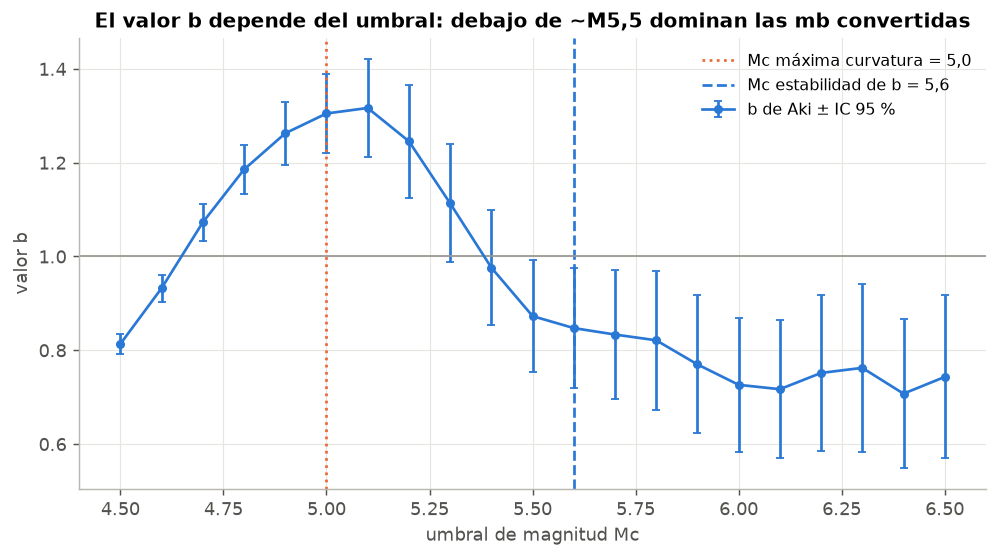

In [5]:
display(Image(config.FIGURAS / '07_estabilidad_valor_b.png'))

Con las magnitudes originales (sin homogeneizar) el problema es parecido:

In [6]:
go = resultados['gutenberg_richter_ecuador_magnitud_original']
pd.DataFrame({'máxima curvatura': go['maxc'], 'estabilidad de b': go['mbs']})

,máxima curvatura,estabilidad de b
mc,4.600,4.500
n,1490.000,1838.000
b,0.974,0.961
a,5.904,5.839
sigma_shi_bolt,0.027,0.023
sigma_aki,0.025,0.022
ic95_bajo,0.921,0.915
ic95_alto,1.026,1.006
ic95_boot_bajo,0.920,0.914
ic95_boot_alto,1.031,1.010


## Comparación con el Cinturón de Fuego

Mismo catálogo (mundo M≥5, 1973–2025) y mismo método para las 13 zonas; para comparar en igualdad se usa un Mc común de 5,5.

In [7]:
cint = pd.read_csv(config.REPORTES / 'valor_b_cinturon.csv')
cint[['zona', 'eventos_m5', 'eventos_m7', 'pct_profundos_70km', 'mc_mbs', 'b_mc_comun', 'b_mc_comun_ic95_bajo', 'b_mc_comun_ic95_alto', 'n_mc_comun']].round(3)

,zona,eventos_m5,eventos_m7,pct_profundos_70km,mc_mbs,b_mc_comun,b_mc_comun_ic95_bajo,b_mc_comun_ic95_alto,n_mc_comun
0,Ecuador,540,14,28.0,5.2,0.883,0.760,1.006,215
1,México,765,23,11.1,5.2,0.957,0.842,1.073,335
2,Colombia–Panamá,842,7,17.6,5.4,1.055,0.955,1.155,347
3,Chile centro-sur,1580,15,11.5,5.6,1.128,1.034,1.222,644
4,Centroamérica,1299,14,25.6,5.7,1.130,1.030,1.230,571
5,Perú,1292,21,37.3,5.2,1.132,1.019,1.245,515
6,Alaska–Aleutianas,2098,17,8.2,5.6,1.141,1.062,1.221,860
7,Japón,3972,32,11.8,5.5,1.156,1.100,1.213,1625
8,Nueva Zelanda,600,7,25.8,5.6,1.210,1.042,1.378,255
9,Chile norte,1949,16,54.4,5.8,1.212,1.117,1.306,762


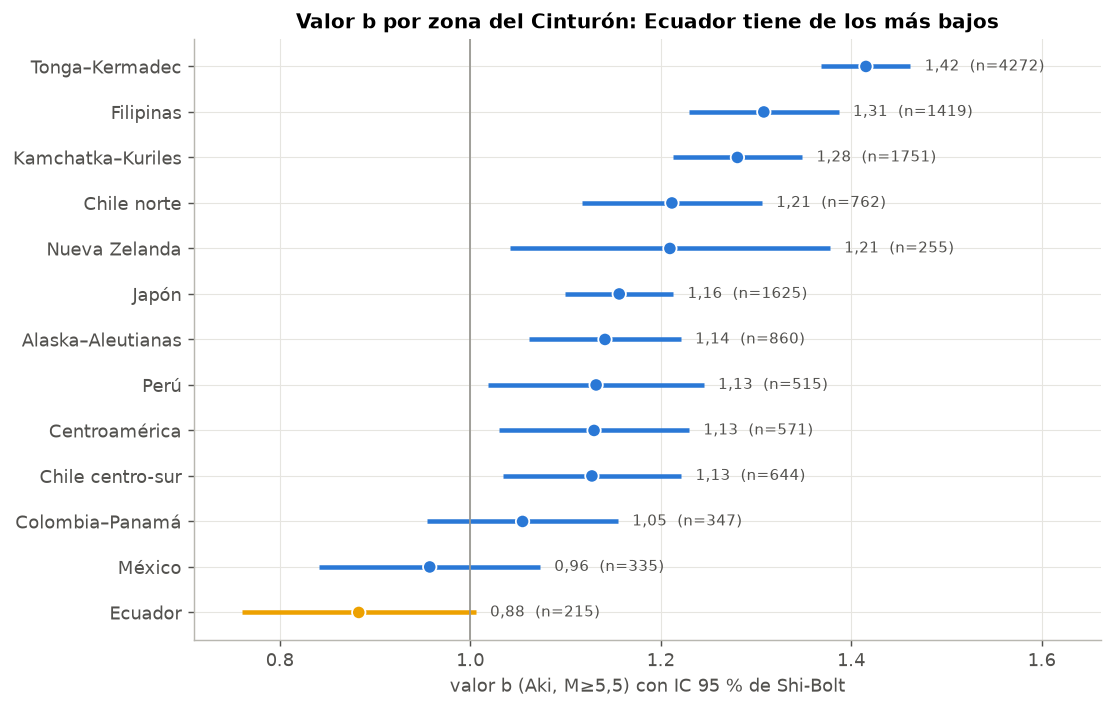

In [8]:
display(Image(config.FIGURAS / '09_valor_b_por_zona.png'))

**Línea base contra el modelo:** ¿la recta, extrapolada hasta M7, reproduce cuántos M≥7 hubo de verdad?

In [9]:
cint[['zona', 'tasa_m7_gr', 'tasa_m7_empirica', 'retorno_m7_gr_anios']].assign(cociente=lambda d: d.tasa_m7_empirica / d.tasa_m7_gr).round(3)

,zona,tasa_m7_gr,tasa_m7_empirica,retorno_m7_gr_anios,cociente
0,Ecuador,0.192,0.264,5.203,1.374
1,México,0.232,0.434,4.320,1.875
2,Colombia–Panamá,0.171,0.132,5.840,0.771
3,Chile centro-sur,0.247,0.283,4.046,1.145
4,Centroamérica,0.217,0.264,4.599,1.215
5,Perú,0.195,0.396,5.137,2.036
6,Alaska–Aleutianas,0.315,0.321,3.177,1.019
7,Japón,0.565,0.604,1.771,1.069
8,Nueva Zelanda,0.074,0.132,13.559,1.791
9,Chile norte,0.219,0.302,4.571,1.380


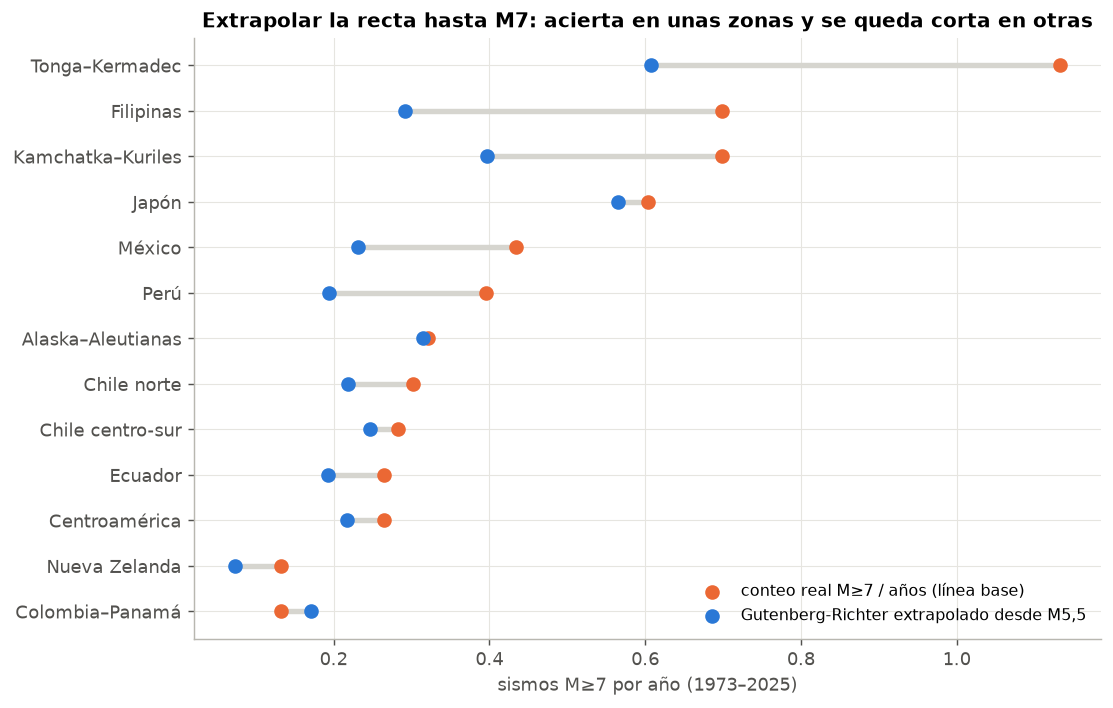

In [10]:
display(Image(config.FIGURAS / '10_m7_gr_vs_conteo.png'))